### Analyse

A faire :
- EDA avec graphiques
    - Histogrammes
    - Boîtes à moustache
    - Histogramme comparé par série
    - Histogramme comparé par plateforme
- Moyenne avec intervalles de confiance
- Ecart-type

In [1]:
import numpy as np 
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_csv("df_clean.csv")
df

,avis,dates,series,notes,plateforme
0,"Un début de saison (Ép. 01) très réussi, qui t...",2026-02-19,A Knight of the Seven Kingdoms,10.0,Allocine
1,J’y ai trouvé du génie ! Pour ceux qui disent ...,2026-02-07,A Knight of the Seven Kingdoms,10.0,Allocine
2,Quelle drôle d’idée de faire un schema aussi c...,2026-02-24,A Knight of the Seven Kingdoms,7.0,Allocine
3,Seule le format est décevant. Seulement 6 épis...,2026-02-08,A Knight of the Seven Kingdoms,9.0,Allocine
4,Je ne suis probablement pas très objectif conc...,2026-02-08,A Knight of the Seven Kingdoms,8.0,Allocine
...,...,...,...,...,...
1602,Mediocre filmmaking - Weak script in combinati...,2025-10-29,King & Conqueror,1.0,Imdb
1603,drunk history - As many other reviewers have n...,2026-02-02,King & Conqueror,3.0,Imdb
1604,I get it... -,2026-02-26,King & Conqueror,7.0,Imdb
1605,Realism... - Earl's military crews count 5-8 s...,2026-03-02,King & Conqueror,3.0,Imdb


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1607 entries, 0 to 1606
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   avis        1607 non-null   object 
 1   dates       1607 non-null   object 
 2   series      1607 non-null   object 
 3   notes       1607 non-null   float64
 4   plateforme  1607 non-null   object 
dtypes: float64(1), object(4)
memory usage: 62.9+ KB


In [4]:
print(df['series'].value_counts(), '\n')
print(df['series'].value_counts(normalize=True))

# Prépondérance importante de la série 'A knight of the seven kingdoms'

series
A Knight of the Seven Kingdoms    1404
King & Conqueror                   203
Name: count, dtype: int64 

series
A Knight of the Seven Kingdoms    0.873678
King & Conqueror                  0.126322
Name: proportion, dtype: float64


In [5]:
print(df['plateforme'].value_counts(), '\n')
print(df['plateforme'].value_counts(normalize=True))

# Prépondérance importante de la plateforme Imdb

plateforme
Imdb        1412
Allocine     195
Name: count, dtype: int64 

plateforme
Imdb        0.878656
Allocine    0.121344
Name: proportion, dtype: float64


In [6]:
display(pd.crosstab(df['series'], df['plateforme']))
print()
display(pd.crosstab(df['series'], df['plateforme'], normalize=True))

# Prépondérance importante de la plateforme Imdb

plateforme,Allocine,Imdb
series,,
A Knight of the Seven Kingdoms,165,1239
King & Conqueror,30,173


plateforme,Allocine,Imdb
series,,
A Knight of the Seven Kingdoms,0.102676,0.771002
King & Conqueror,0.018668,0.107654


In [7]:
display(df.describe())
print()
print('Statistiques sur la plateforme Allociné :\n', df[df['plateforme'] == 'Allocine'].describe() )
print()
print('Statistiques sur la plateforme Imdb :\n', df[df['plateforme'] == 'Imdb'].describe())

# Différences importantes de notation entre allociné et imdb : imdb note nettement plus haut 
# Différence de public ou de pays (fr vs usa) ?

,notes
count,1607.000000
mean,7.794648
std,3.041047
min,1.000000
25%,6.000000
50%,9.000000
75%,10.000000
max,10.000000



Statistiques sur la plateforme Allociné :
             notes
count  195.000000
mean     6.620513
std      3.010221
min      1.000000
25%      4.000000
50%      7.000000
75%      9.000000
max     10.000000

Statistiques sur la plateforme Imdb :
              notes
count  1412.000000
mean      7.956799
std       3.010537
min       1.000000
25%       7.000000
50%      10.000000
75%      10.000000
max      10.000000


In [8]:
print('Statistiques sur la série : A knight of the seven kingdoms :\n', df[df['series'] == 'A Knight of the Seven Kingdoms'].describe() )
print()
print('Statistiques sur la série King & Conquerer :\n', df[df['series'] == 'King & Conqueror'].describe())

# Différences importantes de notation entre allociné et imdb : imdb note nettement plus haut 
# Différence de public ou de pays (fr vs usa) ?

Statistiques sur la série : A knight of the seven kingdoms :
              notes
count  1404.000000
mean      8.287749
std       2.727039
min       1.000000
25%       8.000000
50%      10.000000
75%      10.000000
max      10.000000

Statistiques sur la série King & Conquerer :
             notes
count  203.000000
mean     4.384236
std      2.914652
min      1.000000
25%      2.000000
50%      4.000000
75%      7.000000
max     10.000000


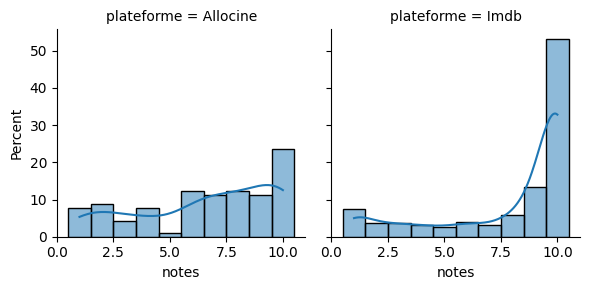

In [9]:
# Visualisons les distributions

g = sns.FacetGrid(df, col="plateforme")
g.map(sns.histplot, 'notes', bins=10, kde=True, stat='percent', discrete=True);

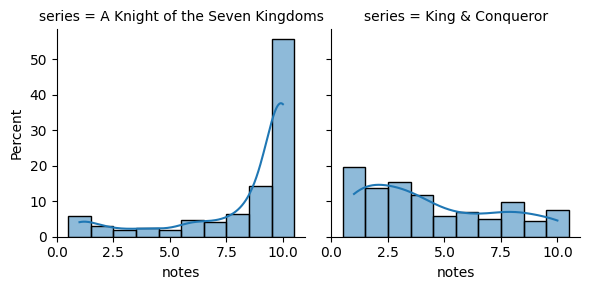

In [10]:
g = sns.FacetGrid(df, col="series")
g.map(sns.histplot, 'notes', bins=10, kde=True, stat='percent', discrete=True);

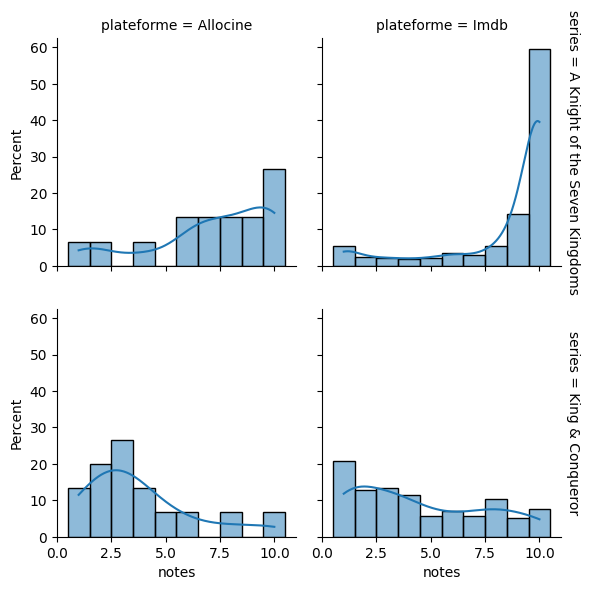

In [11]:
g = sns.FacetGrid(df, col="plateforme", row='series', margin_titles=True)
g.map(sns.histplot, "notes", stat='percent', kde=True, discrete=True);

Pour les deux plateformes, les notes élevées (8 à 10) sont très fortes pour 'A knight of the seven kingdoms' tandis que les notes très faibles (0 à 2) sont plus choisies pour 'King & Conquerer'.

Imdb, plateforme Américaine, a plus de notes positives pour les deux séries. Mais le nombre de 10 pour 'A knight of the seven Kingdom' est impressionant (60%) : la série a été un énorme succès critique.

A l'inverse, Allociné, plateforme française, les notes tendent à être moins positives. C'est particulièrement le cas pour 'King & Conquerer', où les notes entre 0 et 4 sont sur-représentées.

La médiane est révélatrice : elle est de 10 pour Imdb et 7 pour allociné.

annee-mois
202508      87
202509      51
202510      13
202511      21
202512       3
202601     210
202602    1081
202603     141
Name: count, dtype: int64


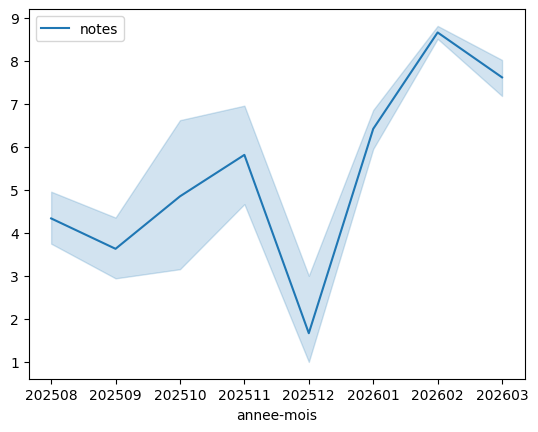

In [12]:
# Regardons si la date a eu un impact sur les notes données

df['dates'] = pd.to_datetime(df['dates'])

df['annee-mois'] = df['dates'].dt.strftime('%Y%m')
print(df['annee-mois'].value_counts().sort_index())

df_dates = df.set_index('annee-mois').sort_index()

sns.lineplot(data=df_dates.sort_index());

# Nous observons une dynamique différente entre la fin de l'année dernière, avec des notes globalement
# inférieurs à 5, et 2026, où les notes remontent fortement.

In [13]:
# Regardons de plus près les statistiques par mois.

df.groupby(['annee-mois'])['notes'].describe()

,count,mean,std,min,25%,50%,75%,max
annee-mois,,,,,,,,
202508,87.0,4.333333,2.859772,1.0,2.0,4.0,7.0,10.0
202509,51.0,3.627451,2.734672,1.0,1.0,3.0,4.5,10.0
202510,13.0,4.846154,3.411895,1.0,2.0,4.0,8.0,10.0
202511,21.0,5.809524,2.786020,1.0,4.0,6.0,8.0,10.0
202512,3.0,1.666667,1.154701,1.0,1.0,1.0,2.0,3.0
202601,210.0,6.414286,3.423083,1.0,3.0,8.0,10.0,10.0
202602,1081.0,8.653099,2.492380,1.0,9.0,10.0,10.0,10.0
202603,141.0,7.609929,2.509334,1.0,6.0,8.0,10.0,10.0


Dates de sortie des épisodes : 
24 août 2025 au 5 octobre pour King & Conquer sur BBC One, du 19 janvier au 23 février 2026 pour A knight of the seven kingdoms.

Le mois de février, la médiane à 10 est impressionnantes. Deux hypothèses ici : 
- Les épisodes sortis en février ont eu un excellent accueil.
- Une campagne pour promouvoir la série a eu lieu pour mettre de bonnes notes, notamment sur Imdb.

Le Quartile de 25% à 9 me met la puce à l'oreille. 

Vérifions si nous retrouvons les mêmes tendances sur les deux plateformes pour la série 'A Knight of the Seven Kingdoms'.

In [14]:
df[df['dates'].dt.year == 2026]

,avis,dates,series,notes,plateforme,annee-mois
0,"Un début de saison (Ép. 01) très réussi, qui t...",2026-02-19,A Knight of the Seven Kingdoms,10.0,Allocine,202602
1,J’y ai trouvé du génie ! Pour ceux qui disent ...,2026-02-07,A Knight of the Seven Kingdoms,10.0,Allocine,202602
2,Quelle drôle d’idée de faire un schema aussi c...,2026-02-24,A Knight of the Seven Kingdoms,7.0,Allocine,202602
3,Seule le format est décevant. Seulement 6 épis...,2026-02-08,A Knight of the Seven Kingdoms,9.0,Allocine,202602
4,Je ne suis probablement pas très objectif conc...,2026-02-08,A Knight of the Seven Kingdoms,8.0,Allocine,202602
...,...,...,...,...,...,...
1600,Too far from history - Could have done a bette...,2026-01-15,King & Conqueror,5.0,Imdb,202601
1603,drunk history - As many other reviewers have n...,2026-02-02,King & Conqueror,3.0,Imdb,202602
1604,I get it... -,2026-02-26,King & Conqueror,7.0,Imdb,202602
1605,Realism... - Earl's military crews count 5-8 s...,2026-03-02,King & Conqueror,3.0,Imdb,202603


In [15]:
# Création d'un dataframe ciblé sur 2026 et A kniht of the seven kindgoms
df_2026_knight = df.loc[(df['dates'].dt.year == 2026) & (df['series'] == 'A Knight of the Seven Kingdoms')]
df_2026_knight

,avis,dates,series,notes,plateforme,annee-mois
0,"Un début de saison (Ép. 01) très réussi, qui t...",2026-02-19,A Knight of the Seven Kingdoms,10.0,Allocine,202602
1,J’y ai trouvé du génie ! Pour ceux qui disent ...,2026-02-07,A Knight of the Seven Kingdoms,10.0,Allocine,202602
2,Quelle drôle d’idée de faire un schema aussi c...,2026-02-24,A Knight of the Seven Kingdoms,7.0,Allocine,202602
3,Seule le format est décevant. Seulement 6 épis...,2026-02-08,A Knight of the Seven Kingdoms,9.0,Allocine,202602
4,Je ne suis probablement pas très objectif conc...,2026-02-08,A Knight of the Seven Kingdoms,8.0,Allocine,202602
...,...,...,...,...,...,...
1429,"The comeback of GOT - Juste imagine, you have ...",2026-02-23,A Knight of the Seven Kingdoms,10.0,Imdb,202602
1430,A Beauty of Westeros - I have a close friend w...,2026-02-23,A Knight of the Seven Kingdoms,10.0,Imdb,202602
1431,Old stories - I feel like this is not a series...,2026-02-23,A Knight of the Seven Kingdoms,4.0,Imdb,202602
1432,Very bad show - I don't understand the message...,2026-02-20,A Knight of the Seven Kingdoms,1.0,Imdb,202602


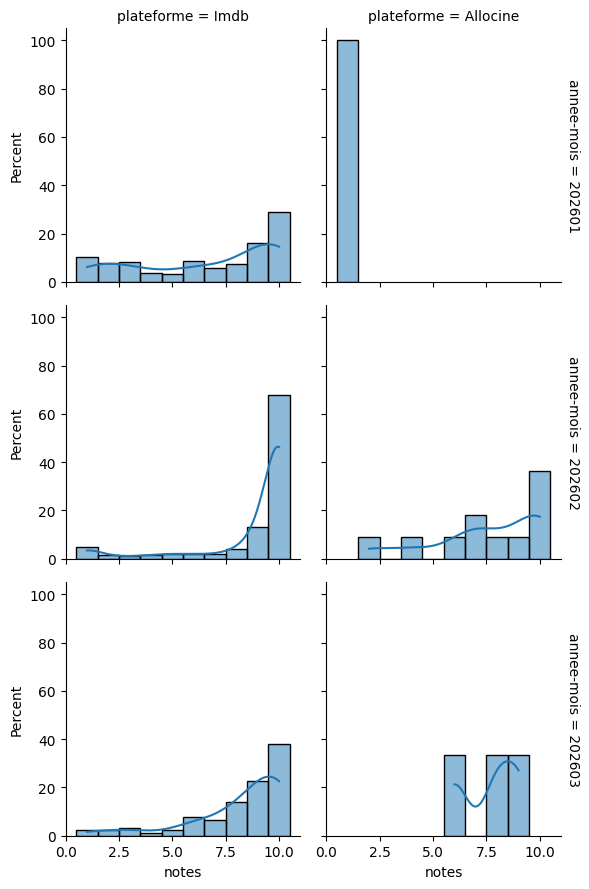

In [16]:
g = sns.FacetGrid(df_2026_knight.sort_values('annee-mois'), col="plateforme", \
                  row='annee-mois', margin_titles=True)
g.map(sns.histplot, "notes", stat='percent', kde=True, discrete=True);

# Comparer janvier / février / mars.
# Pour ce faire, prendre toutes les dates de 2026.

Je pense que mes deux hypothèses sont justes :
1. Les épisodes 3, 4, et 5 de la série ont reçu un très bon accueil : ce sont les meilleurs avec des notes tous supérieurs à 9 dans Imdb.
2. Il est aussi possible que les plus fans de l'univers GOAT aient regardé les épisodes dès leur sortie, et qu'ils soient le plus venus rapidement donner une note positive. Il y a peut-être eu un effet de mode en février.
3. En revanche, je trouve la différence entre février et mars trop différente (environ 60% et 40% de notes à 10). 

Je pense que la hype explique ces notes très fortes. Mais par soucis de pédagogie, je vais baisser le poids des notes données 

In [17]:
# Statistiques avant modification

print("Statistiques par série")
display(df.groupby(['series'])[('notes')].describe())
print()
print("Statistiques par série x plateforme")
display(df.groupby(['plateforme', 'series'])[('notes')].describe())

Statistiques par série


,count,mean,std,min,25%,50%,75%,max
series,,,,,,,,
A Knight of the Seven Kingdoms,1404.0,8.287749,2.727039,1.0,8.0,10.0,10.0,10.0
King & Conqueror,203.0,4.384236,2.914652,1.0,2.0,4.0,7.0,10.0



Statistiques par série x plateforme


count      mean       std  min  \
plateforme series                                                            
Allocine   A Knight of the Seven Kingdoms   165.0  7.133333  2.810115  1.0   
           King & Conqueror                  30.0  3.800000  2.496895  1.0   
Imdb       A Knight of the Seven Kingdoms  1239.0  8.441485  2.679653  1.0   
           King & Conqueror                 173.0  4.485549  2.975886  1.0   

                                           25%   50%    75%   max  
plateforme series                                                  
Allocine   A Knight of the Seven Kingdoms  6.0   8.0  10.00  10.0  
           King & Conqueror                2.0   3.0   4.75  10.0  
Imdb       A Knight of the Seven Kingdoms  8.0  10.0  10.00  10.0  
           King & Conqueror                2.0   4.0   7.00  10.0

Modifications : donner un poids de 0,8 à la réponse lorsque la note est de 10 pour 'A Knight of the Seven Kingdoms' en février, et  1 pour les autres

Une pondération à 80% (baisse de 20%) part d'une hypothèse prudente, que la plupart des notes sont sincères, et que, s'il y a eu une campagne, elle se situe à la marge.

In [18]:
df['poids'] = 1.0
df.loc[
    (df['plateforme'] == 'Imdb') 
    & (df['series'] == 'A Knight of the Seven Kingdoms') 
    & (df['notes'] == 10)
    & (df['annee-mois'] == '202602')
    , 'poids'
    ] = 0.8

df['poids'].value_counts()

poids
1.0    961
0.8    646
Name: count, dtype: int64

In [34]:
# Nouvelle moyenne pondérée de 'a Knight of the Seven Kingdoms'

df_knight = df[df['series'] == 'A Knight of the Seven Kingdoms']

df_knight_mean = (df_knight['notes'] * df_knight['poids']).sum() / df_knight['poids'].sum()

print(round(df_knight_mean, 2))

# Nous passons donc de 8,44 à 8,11.

8.11


Calculons maintenant les intervalles de confiance pour les deux séries.

Avec deux cas de figure : 
1. King & Conquerer : pas de modification du poids des réponses
2. A Knight of the Seven Kingdoms : modifications du poids, donc de l'effectif de réponses.

https://claude.ai/chat/f112ba51-f00a-46da-9286-042acd2bc990
https://matthwilhelm.github.io/ProbaStat/Tutoriel_Python.html
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html


In [36]:
from scipy.stats import t
from statistics import variance, mean 
from scipy.stats import skew, kurtosis

In [25]:
df_king['notes']

165     3.0
166     6.0
167     1.0
168     3.0
169     3.0
       ... 
1602    1.0
1603    3.0
1604    7.0
1605    3.0
1606    1.0
Name: notes, Length: 203, dtype: float64

In [37]:
print(skew(df_king['notes']))     # asymétrie — idéalement proche de 0
print(kurtosis(df_king['notes'])) # aplatissement — problématique si très élevé

0.5440450572124065
-0.9833728907989512


In [ ]:
# Cas 1 : King & Conqueror, sans pondération des notes
df_king = df[df['series'] == 'King & Conqueror']

def int_ech(values, conf=0.95):
    
    n = len(values)
    m = np.mean(values)
    s = np.var(values, ddof=1)

    alpha_half = 1 - (1 - conf) / 2
    ddl = n - 1

    intervalle = np.sqrt(s / n) * t.ppf(alpha_half, ddl)

    return intervalle

intervalle_king = int_ech(df_king['notes'])
intervalle_king_up = np.mean(df_king['notes']) + intervalle_king
intervalle_king_down = np.mean(df_king['notes']) - intervalle_king

print('Intervalle de confiance King & Conqueror : [', intervalle_king_down,'-', intervalle_king_up, ']' )

Intervalle de confiance King & Conqueror : [ 3.980872987897884 - 4.787599918506057 ]


In [38]:
print(skew(df_knight['notes']))     # asymétrie — idéalement proche de 0
print(kurtosis(df_knight['notes'])) # aplatissement — problématique si très élevé

-1.615940275733987
1.3262421032269636


In [35]:
# Pour A Knight of the Seven Kingdoms

n= np.sum(df_knight['poids']) # Prendre en compte le nouveau poids décidé
m = df_knight_mean # Moyenne agrégée
s = np.var(df_knight['notes'], ddof=1)

conf = 0.95 # Degré de confiance

alpha_half = 1 - (1 - conf) / 2
ddl = n - 1

intervalle_knight = np.sqrt(s / n) * t.ppf(alpha_half, ddl)
intervalle_knight_up = np.mean(df_knight['notes']) + intervalle_knight
intervalle_knight_down = np.mean(df_knight['notes']) - intervalle_knight

print('Intervalle de confiance A Knight of the Seven Kingdoms : [', intervalle_knight_down,'-', intervalle_knight_up, ']' )

Intervalle de confiance A Knight of the Seven Kingdoms : [ 8.13790807390049 - 8.437590501598084 ]


In [43]:
df_knight_mean

np.float64(8.114213994352054)

In [ ]:
from scipy.stats import bootstrap

# Ne pas prendre en compte parce que la moyenne n'est pas bonne
result = bootstrap(
    (df_knight['notes'].values,),
    np.mean,
    confidence_level=0.95,
    n_resamples=9999,
    method='percentile'
)
print(result.confidence_interval)

ConfidenceInterval(low=np.float64(8.145299145299145), high=np.float64(8.43019943019943))
